# Лабораторная работа № 1. Регрессия

**Цель:** предсказание качества красного вина по физико-химическим характеристикам.
Основная модель — обычная линейная регрессия `LinearRegression`.
Случайный лес и градиентный бустинг включены для сравнительного анализа.
Основная метрика — RMSE, дополнительная — MAE. Порог задания: RMSE < 0.70.

**Данные:** `winequality-red.csv`, Wine Quality, UCI Machine Learning Repository.
Белое вино в данном эксперименте не используется; полученные метрики относятся к красному вину.

**Источники:** [материалы курса](https://github.com/lesopylka/ml_course_mai),
[Wine Quality — UCI](https://archive.ics.uci.edu/dataset/186/wine+quality).
Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009).
[DOI: 10.24432/C56S3T](https://doi.org/10.24432/C56S3T).

## 1. Загрузка и подготовка данных

Исходные CSV находятся в `data/wine_quality`. Версии библиотек зафиксированы в `requirements.txt`.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})
%matplotlib inline

print('Версии: pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

Версии: pandas 2.3.3 | scikit-learn 1.6.1


In [2]:
DATA_DIR = Path('data/wine_quality')
if not DATA_DIR.exists():
    DATA_DIR = Path('regression/data/wine_quality')

raw_data = pd.read_csv(DATA_DIR / 'winequality-red.csv', sep=';')
print('Размер исходного набора:', raw_data.shape)
display(raw_data.head())

Размер исходного набора: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Набор содержит 1 599 наблюдений, 11 числовых входных признаков и целевую переменную `quality`.
Предсказания перед оценкой не округляются.

| Признак | Описание |
|---|---|
| `fixed acidity` | Нелетучая кислотность |
| `volatile acidity` | Летучая кислотность |
| `citric acid` | Лимонная кислота |
| `residual sugar` | Остаточный сахар |
| `chlorides` | Хлориды |
| `free sulfur dioxide` | Свободный диоксид серы |
| `total sulfur dioxide` | Общий диоксид серы |
| `density` | Плотность |
| `pH` | Показатель кислотности |
| `sulphates` | Сульфаты |
| `alcohol` | Содержание алкоголя |
| `quality` | Целевая оценка качества |

In [3]:
print('Пропущенных значений:', raw_data.isna().sum().sum())
print('Полных повторов строк:', raw_data.duplicated().sum())
display(raw_data.dtypes.to_frame('Тип данных'))

# Удаление точных повторов до разбиения.
data = raw_data.drop_duplicates().reset_index(drop=True)
X = data.drop(columns='quality')
y = data['quality']

print('После удаления повторов:', data.shape)
print('Повторов наборов признаков:', X.duplicated().sum())
assert not X.isna().any().any(), 'Обнаружены пропуски.'
assert not X.duplicated().any(), 'Обнаружены повторяющиеся наборы признаков.'

Пропущенных значений: 0
Полных повторов строк: 240


,Тип данных
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


После удаления повторов: (1359, 12)
Повторов наборов признаков: 0


Пропуски отсутствуют, все признаки числовые. Удалено 240 полных повторов;
осталось 1 359 наблюдений. Повторов наборов входных признаков после очистки нет.
Удаление копий исключает их одновременное попадание в обучение и проверку.
Качество оценивается на уникальных наблюдениях красного вина.

## 2. Разбиение выборки

Выполнено случайное разбиение 80/20 с `random_state=42`: 1 087 объектов train и 272 test.
Соотношение сохраняет основную часть наблюдений для обучения и отдельную проверочную выборку.
В данных отсутствуют временные метки и идентификаторы производителей для обоснования другого разбиения.
Seed и доля test не подбираются по результатам метрик.

Зависимости исследуются на train. Качество моделей до итоговой проверки оценивается общей
пятикратной кросс-валидацией внутри train. Основная модель зафиксирована как линейная регрессия.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
train_data = X_train.copy()
train_data['quality'] = y_train

print('Train:', len(X_train), 'строк;', X_train.shape[1], 'признаков')
print('Test: ', len(X_test), 'строк;', X_test.shape[1], 'признаков')
assert set(X_train.index).isdisjoint(X_test.index)

Train: 1087 строк; 11 признаков
Test:  272 строк; 11 признаков


Многократный выбор настроек по одной тестовой выборке приводит к подстройке под неё и оптимистичной метрике.
Поэтому при подготовке данного эксперимента проверочные фолды выделяются внутри train,
а test используется для итоговой оценки фиксированных моделей.

## 3. Исследовательский анализ обучающей выборки

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1087.0,8.293,1.726,4.600,7.100,7.900,9.100,15.900
volatile acidity,1087.0,0.528,0.178,0.160,0.390,0.520,0.640,1.580
citric acid,1087.0,0.273,0.195,0.000,0.100,0.260,0.420,1.000
residual sugar,1087.0,2.525,1.366,0.900,1.900,2.200,2.600,15.500
chlorides,1087.0,0.090,0.052,0.012,0.070,0.080,0.091,0.611
free sulfur dioxide,1087.0,15.741,10.336,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1087.0,46.849,33.300,6.000,22.000,38.000,63.000,289.000
density,1087.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1087.0,3.310,0.152,2.740,3.210,3.310,3.400,3.900
sulphates,1087.0,0.660,0.174,0.330,0.550,0.620,0.730,2.000


,Количество на train
quality,
3,6
4,42
5,457
6,432
7,136
8,14


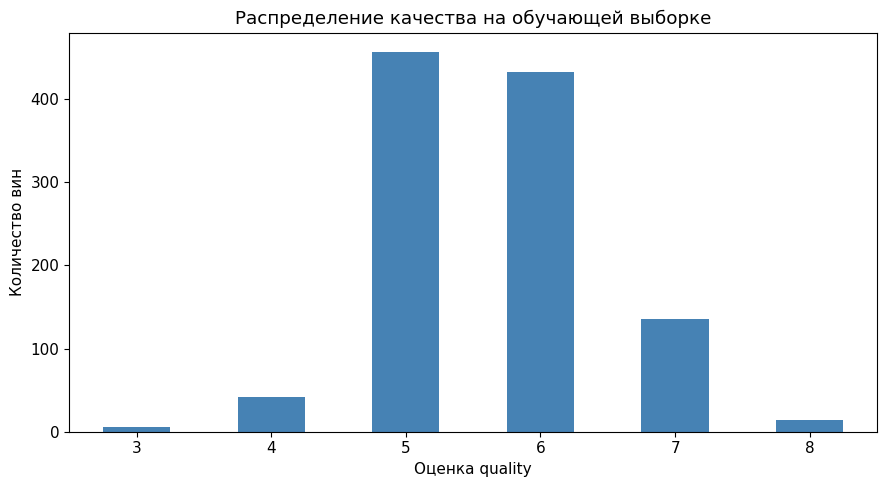

In [5]:
display(train_data.describe().T.round(3))

quality_counts = y_train.value_counts().sort_index()
display(quality_counts.to_frame('Количество на train'))
quality_counts.plot.bar(color='steelblue', rot=0)
plt.xlabel('Оценка quality')
plt.ylabel('Количество вин')
plt.title('Распределение качества на обучающей выборке')
plt.tight_layout()
plt.show()

Преобладают оценки 5 и 6: 457 и 432 объекта train соответственно.
Оценки 3 и 8 представлены 6 и 14 наблюдениями, поэтому качество на крайних значениях может быть менее устойчивым.
Редкие наблюдения и экстремальные значения признаков сохранены при отсутствии подтверждённых ошибок измерения.
Масштабы признаков различаются; для интерпретации коэффициентов линейной модели используется стандартизация.

,alcohol,volatile acidity,sulphates
quality,,,
3,9.658,0.798,0.600
4,10.224,0.677,0.608
5,9.896,0.577,0.626
6,10.662,0.500,0.672
7,11.469,0.404,0.739
8,11.964,0.415,0.780


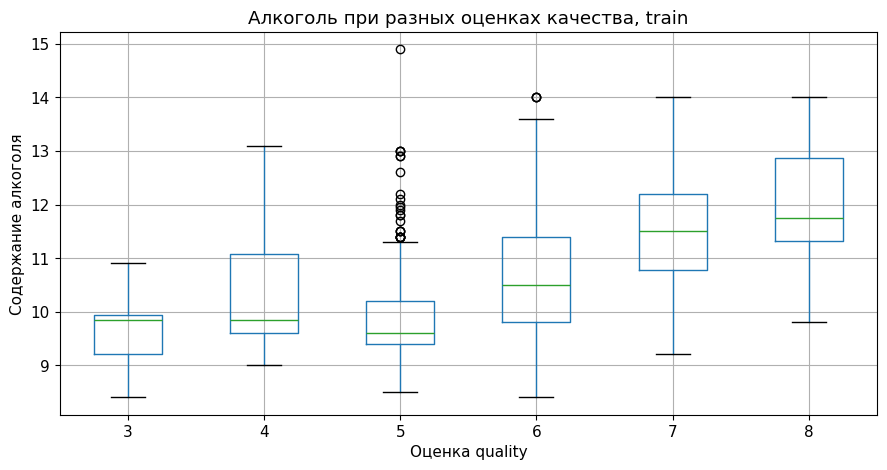

In [6]:
display(train_data.groupby('quality')[
    ['alcohol', 'volatile acidity', 'sulphates']
].mean().round(3))

train_data.boxplot(column='alcohol', by='quality', figsize=(9, 5))
plt.xlabel('Оценка quality')
plt.ylabel('Содержание алкоголя')
plt.title('Алкоголь при разных оценках качества, train')
plt.suptitle('')
plt.tight_layout()
plt.show()

Распределение алкоголя различается между группами качества; при более высоких оценках
наблюдается тенденция к большему содержанию алкоголя. Внутригрупповой разброс и пересечение диапазонов
показывают, что один признак не определяет оценку однозначно. Средние редких групп неустойчивы.

,Корреляция с quality
volatile acidity,-0.377
total sulfur dioxide,-0.203
density,-0.171
chlorides,-0.133
pH,-0.069
free sulfur dioxide,-0.056
residual sugar,0.019
fixed acidity,0.124
citric acid,0.220
sulphates,0.225


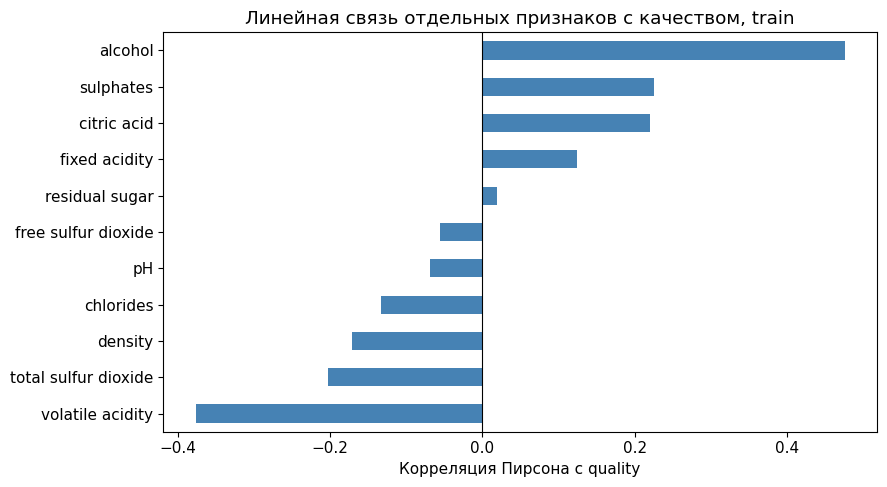

In [7]:
correlations = X_train.corrwith(y_train).sort_values()
display(correlations.to_frame('Корреляция с quality').round(3))
correlations.plot.barh(color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Корреляция Пирсона с quality')
plt.title('Линейная связь отдельных признаков с качеством, train')
plt.tight_layout()
plt.show()

Наиболее выраженная положительная корреляция с `quality` получена у `alcohol` (0.476),
отрицательная — у `volatile acidity` (−0.377).
У `sulphates` (0.225) и `citric acid` (0.220) связь положительная,
у `total sulfur dioxide` (−0.203) — отрицательная.
Указанные признаки сохранены. Слабая попарная корреляция остальных столбцов не исключает их условной полезности.

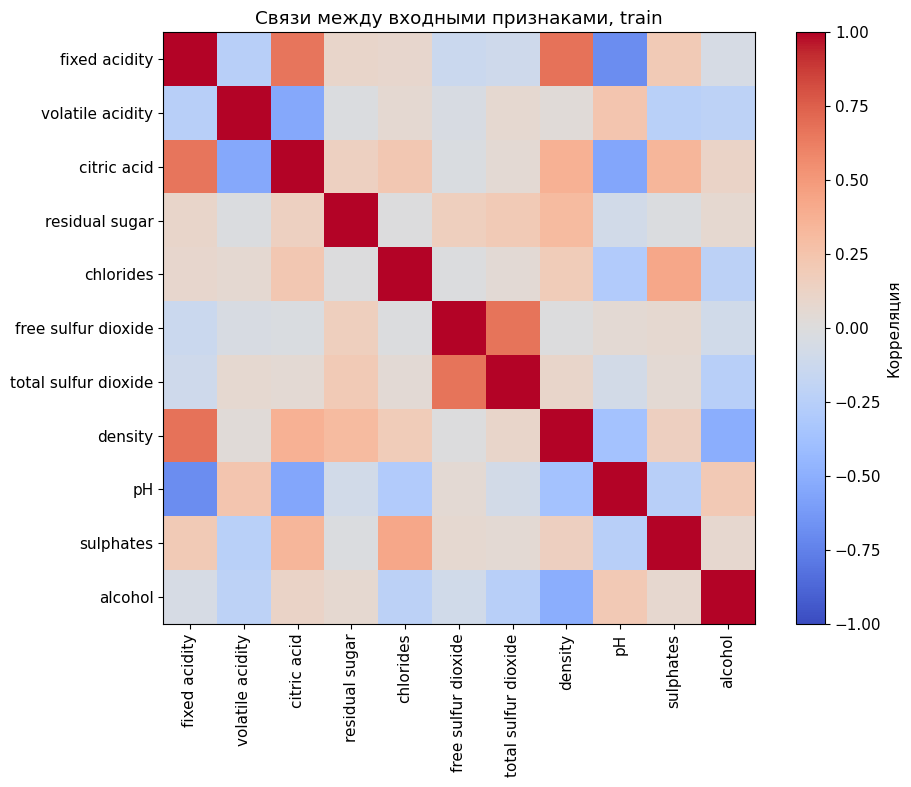

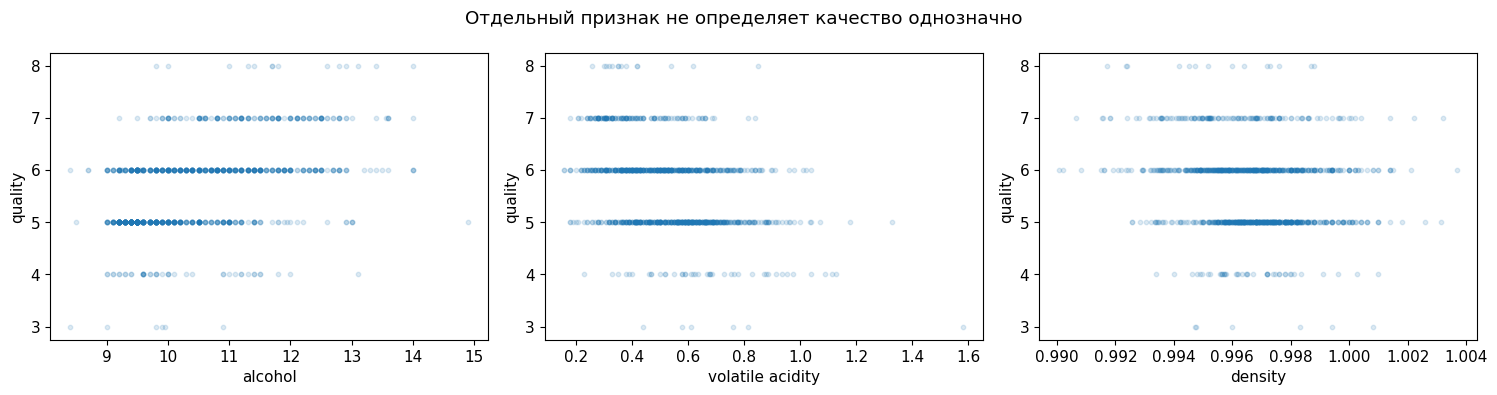

In [8]:
corr_matrix = X_train.corr()
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=90)
ax.set_yticks(range(len(corr_matrix)), corr_matrix.columns)
fig.colorbar(image, ax=ax, label='Корреляция')
ax.set_title('Связи между входными признаками, train')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ['alcohol', 'volatile acidity', 'density']):
    ax.scatter(X_train[feature], y_train, s=10, alpha=0.15)
    ax.set_xlabel(feature)
    ax.set_ylabel('quality')
plt.suptitle('Отдельный признак не определяет качество однозначно')
plt.tight_layout()
plt.show()

Некоторые входные признаки взаимосвязаны, в частности показатели кислотности и содержания диоксида серы.
Поэтому коэффициенты многомерной регрессии могут отличаться по знаку и рангу от попарных корреляций.
Разброс качества при одинаковых значениях отдельного признака обосновывает совместное использование 11 характеристик.

## 4. Метрики и baseline



MAE характеризует среднее абсолютное отклонение в баллах качества. RMSE выражается в тех же единицах
и сильнее реагирует на крупные ошибки вследствие возведения отклонений в квадрат.
Различие метрик связано с неоднородностью модулей ошибок; при наличии крупных промахов RMSE заметно выше MAE.
Основной критерий сравнения — минимальный RMSE.

Baseline предсказывает среднее `y_train`: эта константа минимизирует сумму квадратов ошибок,
а следовательно, MSE и RMSE на обучающей выборке.

In [9]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
print(f'Константа baseline: {y_train.mean():.4f}')

Константа baseline: 5.6366


## 5. Обучение моделей

Основная модель — `Pipeline(StandardScaler(), LinearRegression())`.
Используется обычный метод наименьших квадратов: без регуляризации, полиномиальных признаков и ансамблей в прогнозе.
Стандартизация обеспечивает сопоставимость коэффициентов; её параметры вычисляются
только по обучающей части каждого фолда.

Baseline, случайный лес и градиентный бустинг оценены на тех же фолдах для обязательного сравнения.
Их результаты не используются для замены основной линейной модели.

In [10]:
candidates = {
    'Baseline': DummyRegressor(strategy='mean'),
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(
        n_estimators=500, max_features=0.5,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=3,
        min_samples_leaf=20, subsample=0.8, random_state=RANDOM_STATE
    ),
}

Использована пятикратная кросс-валидация `KFold` с перемешиванием и `random_state=42`.
В таблице приведены средние RMSE и MAE на проверочных фолдах, стандартное отклонение RMSE
между фолдами и средняя обучающая RMSE. Отложенный test в выборе параметров не участвует.

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, model in candidates.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={'RMSE': 'neg_root_mean_squared_error',
                 'MAE': 'neg_mean_absolute_error'},
        return_train_score=True,
        n_jobs=1,
    )
    cv_rows.append({
        'Вариант': name,
        'CV RMSE': -scores['test_RMSE'].mean(),
        'CV MAE': -scores['test_MAE'].mean(),
        'CV std': scores['test_RMSE'].std(),
        'Train RMSE': -scores['train_RMSE'].mean(),
    })

cv_table = pd.DataFrame(cv_rows).set_index('Вариант')
display(cv_table.round(4))

,CV RMSE,CV MAE,CV std,Train RMSE
Вариант,,,,
Baseline,0.8179,0.6916,0.0529,0.8178
Linear Regression,0.6684,0.5175,0.0267,0.6573
Random Forest,0.6557,0.5037,0.0351,0.2421
Gradient Boosting,0.6594,0.5116,0.0267,0.5052


Основная модель: Linear Regression


,CV RMSE,CV MAE,CV std,Train RMSE
Вариант,,,,
Baseline,0.8179,0.6916,0.0529,0.8178
Linear Regression,0.6684,0.5175,0.0267,0.6573
Random Forest,0.6557,0.5037,0.0351,0.2421
Gradient Boosting,0.6594,0.5116,0.0267,0.5052


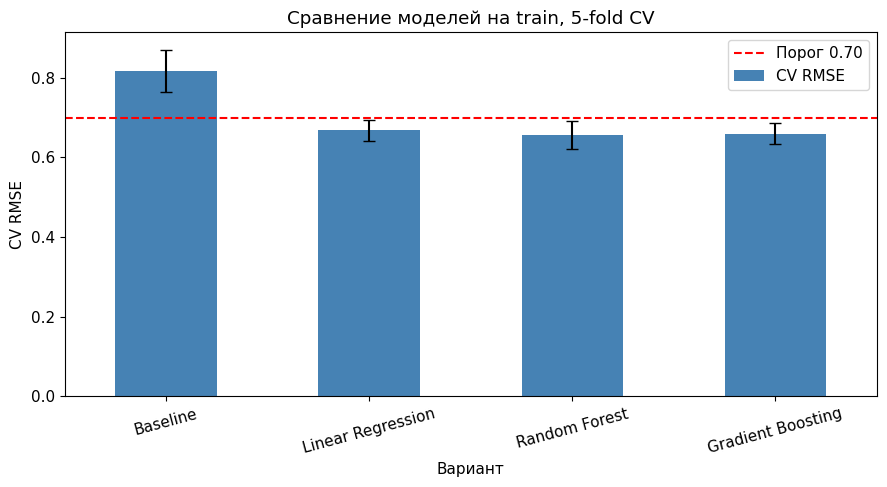

In [12]:
selected_variants = {name: name for name in candidates}
selection_table = cv_table.copy()
main_name = 'Linear Regression'

print('Основная модель:', main_name)
display(selection_table.round(4))

selection_table['CV RMSE'].plot.bar(
    yerr=selection_table['CV std'], capsize=4, color='steelblue', rot=15
)
plt.axhline(0.70, color='red', linestyle='--', label='Порог 0.70')
plt.ylabel('CV RMSE')
plt.title('Сравнение моделей на train, 5-fold CV')
plt.legend()
plt.tight_layout()
plt.show()

Линейная регрессия получила среднюю CV RMSE **0.6684** и CV MAE **0.5175**;
стандартное отклонение RMSE между фолдами — **0.0267**.
Это подтверждает достижимость порога на обучающем пуле при обычной линейной модели.
Итоговая модель зафиксирована как `LinearRegression`; ансамбли остаются сравнительными моделями.

## 6. Итоговое сравнение на тестовой выборке

Выбранные конфигурации обучены на всём train и оценены на общей отложенной тестовой выборке.

In [13]:
fitted_models = {}
test_predictions = {}
test_rows = []

for name, variant in selected_variants.items():
    model = clone(candidates[variant])
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    fitted_models[name] = model
    test_predictions[name] = prediction
    test_rows.append({
        'Модель': name,
        'RMSE': root_mean_squared_error(y_test, prediction),
        'MAE': mean_absolute_error(y_test, prediction),
    })

results = pd.DataFrame(test_rows).set_index('Модель')
display(results.round(4))

baseline_rmse = results.loc['Baseline', 'RMSE']
for name in results.index:
    if name != 'Baseline':
        print(f"{name} лучше baseline: {results.loc[name, 'RMSE'] < baseline_rmse}")

linear_rmse = results.loc[main_name, 'RMSE']
print(f'Основная модель: {main_name}')
print(f'Её test RMSE: {linear_rmse:.4f}; требование RMSE < 0.70: {linear_rmse < 0.70}')
assert linear_rmse < 0.70, 'Локальный порог RMSE < 0.70 не достигнут.'

# Итоговая модель и прогноз для сдачи.
final_model = fitted_models['Linear Regression']
model = final_model
y_pred = test_predictions['Linear Regression']

,RMSE,MAE
Модель,,
Baseline,0.8443,0.7049
Linear Regression,0.6565,0.5041
Random Forest,0.6179,0.4693
Gradient Boosting,0.6137,0.4693


Linear Regression лучше baseline: True
Random Forest лучше baseline: True
Gradient Boosting лучше baseline: True
Основная модель: Linear Regression
Её test RMSE: 0.6565; требование RMSE < 0.70: True


Линейная регрессия получила **RMSE = 0.6565**, **MAE = 0.5041** на локальном test.
Порог RMSE < 0.70 выполнен основной линейной моделью.
Остальные модели представлены в общей таблице на том же разбиении.
Результат относится к красному вину; качество на скрытом тесте преподавателя заранее неизвестно.

## 7. Коэффициенты и важность признаков

### Линейная регрессия

Коэффициенты рассчитаны на стандартизованных признаках: их величины соответствуют изменению прогноза
при увеличении признака на одно стандартное отклонение train при фиксированных остальных признаках.

,Коэффициент
alcohol,0.3340
volatile acidity,-0.1785
sulphates,0.1485
total sulfur dioxide,-0.1236
pH,-0.1215
chlorides,-0.1160
fixed acidity,-0.0497
free sulfur dioxide,0.0487
density,0.0421
citric acid,-0.0191


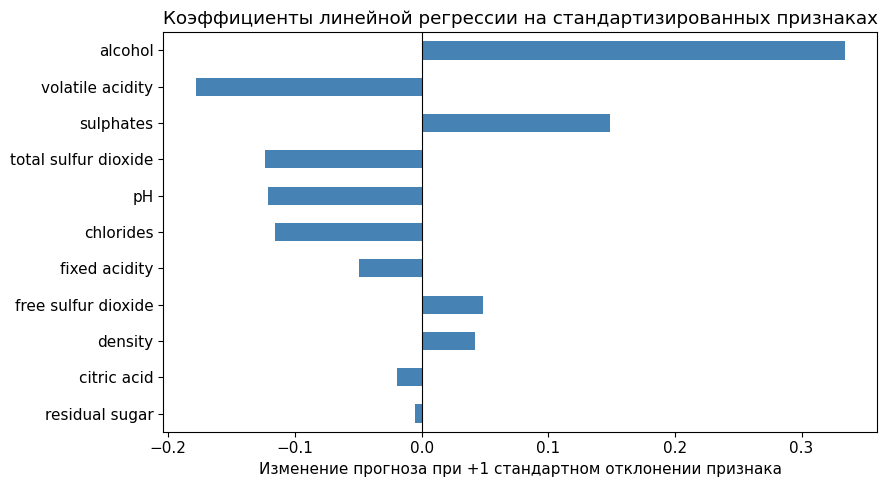

In [14]:
linear_model = fitted_models['Linear Regression'].named_steps['linearregression']
coefficients = pd.Series(linear_model.coef_, index=X_train.columns)
coefficient_order = coefficients.abs().sort_values().index

display(coefficients.loc[coefficient_order[::-1]].to_frame('Коэффициент').round(4))
coefficients.loc[coefficient_order].plot.barh(color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Изменение прогноза при +1 стандартном отклонении признака')
plt.title('Коэффициенты линейной регрессии на стандартизированных признаках')
plt.tight_layout()
plt.show()

Наибольшие модули стандартизованных коэффициентов получены у `alcohol` (+0.334),
`volatile acidity` (−0.178), `sulphates` (+0.148), `total sulfur dioxide` (−0.124)
и `pH` (−0.122). Алкоголь, летучая кислотность и сульфаты согласуются по направлению с корреляционным анализом.
Различия остальных коэффициентов и попарных связей объяснимы совместным учётом взаимосвязанных признаков.
Коэффициенты характеризуют условные изменения прогноза, но не устанавливают причинность.

### Случайный лес и градиентный бустинг

Сопоставлены встроенные важности `feature_importances_`, основанные на уменьшении ошибки при разбиениях деревьев.

,Random Forest,Gradient Boosting
alcohol,0.2257,0.3571
sulphates,0.1381,0.1500
volatile acidity,0.1195,0.1360
total sulfur dioxide,0.0808,0.0797
density,0.0740,0.0365
chlorides,0.0710,0.0556
citric acid,0.0617,0.0320
pH,0.0604,0.0542
fixed acidity,0.0597,0.0298
residual sugar,0.0579,0.0339


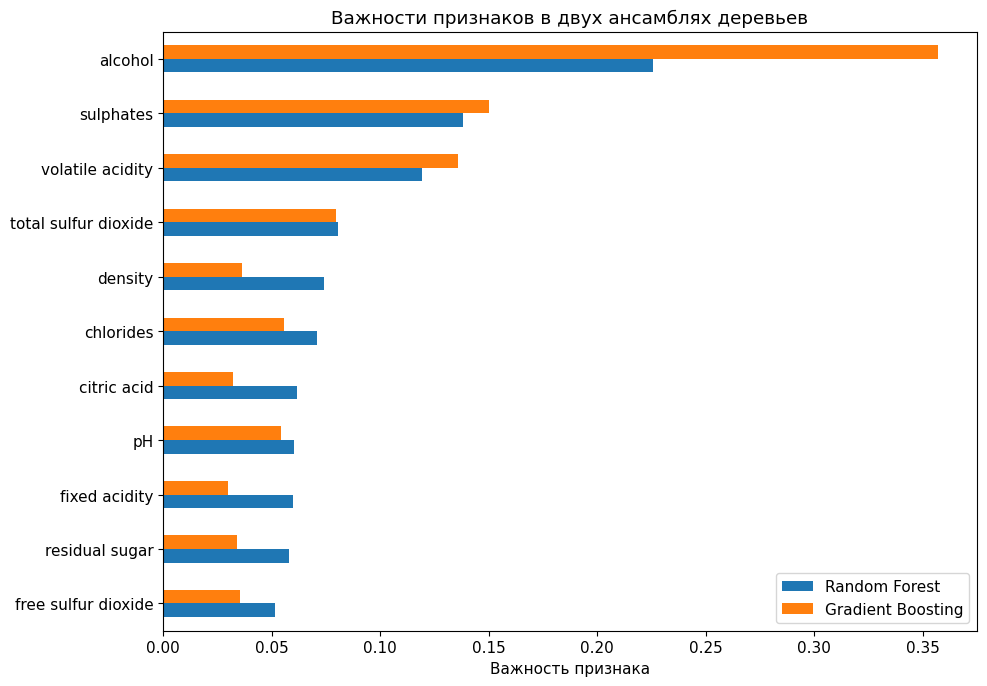

Random Forest — топ-5: alcohol, sulphates, volatile acidity, total sulfur dioxide, density
Gradient Boosting — топ-5: alcohol, sulphates, volatile acidity, total sulfur dioxide, chlorides
Линейная модель — топ-5 по модулю: alcohol, volatile acidity, sulphates, total sulfur dioxide, pH
Корреляция — топ-5 по модулю: alcohol, volatile acidity, sulphates, citric acid, total sulfur dioxide


In [15]:
importances = pd.DataFrame({
    'Random Forest': fitted_models['Random Forest'].feature_importances_,
    'Gradient Boosting': fitted_models['Gradient Boosting'].feature_importances_,
}, index=X_train.columns)

importance_order = importances['Random Forest'].sort_values().index
display(importances.loc[importance_order[::-1]].round(4))
importances.loc[importance_order].plot.barh(figsize=(10, 7))
plt.xlabel('Важность признака')
plt.title('Важности признаков в двух ансамблях деревьев')
plt.tight_layout()
plt.show()

for name in importances.columns:
    print(name, '— топ-5:', ', '.join(importances[name].nlargest(5).index))

print('Линейная модель — топ-5 по модулю:', ', '.join(coefficients.abs().nlargest(5).index))
print('Корреляция — топ-5 по модулю:', ', '.join(correlations.abs().nlargest(5).index))

| Метод | Ведущие признаки |
|---|---|
| Модуль коэффициента линейной регрессии | alcohol, volatile acidity, sulphates, total sulfur dioxide, pH |
| Random Forest | alcohol, sulphates, volatile acidity, total sulfur dioxide, density |
| Gradient Boosting | alcohol, sulphates, volatile acidity, total sulfur dioxide, chlorides |

Все модели выделяют `alcohol`, `volatile acidity` и `sulphates`, что согласуется с первичным анализом.
Важность алкоголя составляет 0.226 у леса и 0.357 у бустинга.
Линейная модель также выделяет pH при слабой попарной корреляции с качеством:
это отражает условную связь при совместном учёте состава.

Коэффициенты и встроенные важности имеют разные масштабы. Связанные признаки могут перераспределять
веса и важности; встроенные важности также зависят от числа доступных порогов разбиения.
Важность не показывает направление связи и не доказывает причинность:
наблюдательные данные не устанавливают эффект независимого изменения одного компонента вина.

## 8. Анализ ошибок линейной регрессии

Проанализированы тестовые предсказания основной модели `LinearRegression`.
Ошибка определена как $\hat y-y$: положительное значение соответствует завышению оценки.

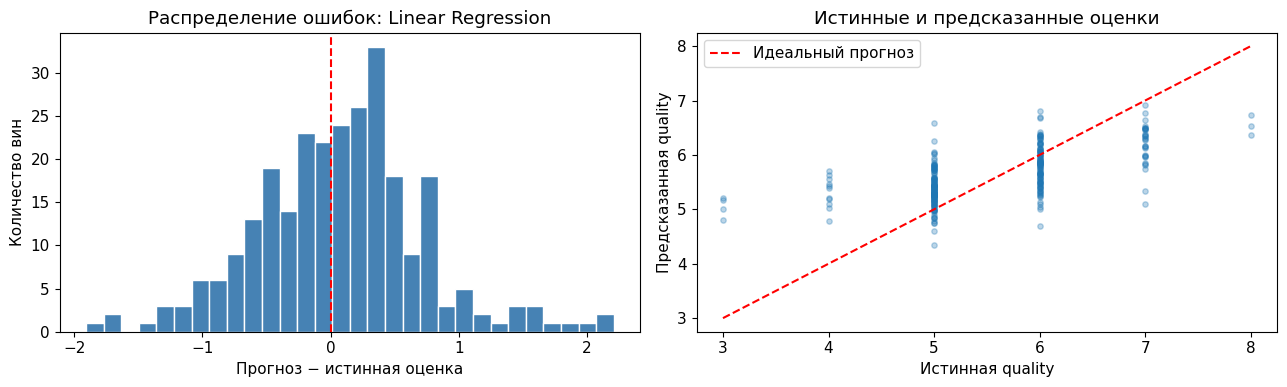

Средняя ошибка со знаком: 0.0677
Доля ошибок не больше 1 балла: 87.9%


In [16]:
linear_prediction = test_predictions[main_name]
errors = X_test.copy()
errors['quality_true'] = y_test
errors['quality_pred'] = linear_prediction
errors['error'] = errors['quality_pred'] - errors['quality_true']
errors['abs_error'] = errors['error'].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(errors['error'], bins=30, color='steelblue', edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_xlabel('Прогноз − истинная оценка')
axes[0].set_ylabel('Количество вин')
axes[0].set_title(f'Распределение ошибок: {main_name}')

axes[1].scatter(y_test, linear_prediction, s=15, alpha=0.3)
low = min(y_test.min(), linear_prediction.min())
high = max(y_test.max(), linear_prediction.max())
axes[1].plot([low, high], [low, high], color='red', linestyle='--', label='Идеальный прогноз')
axes[1].set_xlabel('Истинная quality')
axes[1].set_ylabel('Предсказанная quality')
axes[1].set_title('Истинные и предсказанные оценки')
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Средняя ошибка со знаком: {errors['error'].mean():.4f}")
print(f"Доля ошибок не больше 1 балла: {(errors['abs_error'] <= 1).mean():.1%}")

Средняя ошибка линейной регрессии со знаком составляет **0.0677**: наблюдается небольшое общее завышение.
Для **87.9%** тестовых объектов абсолютная ошибка не превышает одного балла.
При этом имеются крупные положительные и отрицательные отклонения, поэтому малое среднее со знаком
не заменяет RMSE и MAE. На диаграмме заметны завышение низких оценок и занижение высоких.

,Количество test,Количество train,Средний прогноз,Средняя ошибка,MAE,RMSE
quality,,,,,,
3,4,6,5.0466,2.0466,2.0466,2.0531
4,11,42,5.3208,1.3208,1.3208,1.3475
5,120,457,5.3738,0.3738,0.4145,0.5042
6,103,432,5.8046,-0.1954,0.3459,0.4323
7,31,136,6.2045,-0.7955,0.7955,0.8833
8,3,14,6.5400,-1.4600,1.4600,1.4680


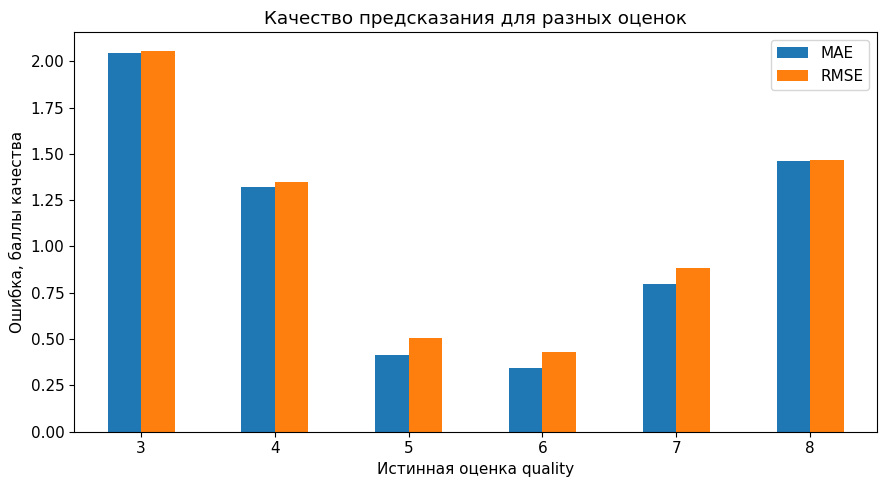

In [17]:
quality_rows = []
for quality, part in errors.groupby('quality_true'):
    quality_rows.append({
        'quality': quality,
        'Количество test': len(part),
        'Количество train': int((y_train == quality).sum()),
        'Средний прогноз': part['quality_pred'].mean(),
        'Средняя ошибка': part['error'].mean(),
        'MAE': mean_absolute_error(part['quality_true'], part['quality_pred']),
        'RMSE': root_mean_squared_error(part['quality_true'], part['quality_pred']),
    })
errors_by_quality = pd.DataFrame(quality_rows).set_index('quality')
display(errors_by_quality.round(4))

errors_by_quality[['MAE', 'RMSE']].plot.bar(rot=0)
plt.xlabel('Истинная оценка quality')
plt.ylabel('Ошибка, баллы качества')
plt.title('Качество предсказания для разных оценок')
plt.tight_layout()
plt.show()

Для частых оценок 5 и 6 MAE равны **0.414** и **0.346** соответственно.
При истинной оценке 3 средний прогноз — **5.047**, при оценке 8 — **6.540**.
Это указывает на завышение низких оценок и занижение высоких.

На train оценка 3 представлена 6 объектами, оценка 8 — 14; на test — 4 и 3 соответственно.
Недостаток примеров крайних значений, ограничения линейной зависимости и неполнота химических признаков
могут объяснять крупные ошибки. Малые размеры групп делают их метрики неустойчивыми.

### Наибольшие ошибки линейной регрессии

Приведены пять крупнейших абсолютных ошибок и характеристики соответствующих вин.
Три примера сопоставлены с диапазоном 5–95-го процентилей train.

In [18]:
worst = errors.nlargest(5, 'abs_error')
display(worst.round(4))

train_lower = X_train.quantile(0.05)
train_upper = X_train.quantile(0.95)
for index, row in worst.head(3).iterrows():
    features = row[X_train.columns]
    unusual = features.index[
        (features < train_lower) | (features > train_upper)
    ].tolist()
    direction = 'завышена' if row['error'] > 0 else 'занижена'
    print(f"Строка {index}: true={row['quality_true']:.0f}, "
          f"pred={row['quality_pred']:.3f}, оценка {direction}.")
    print('  Таких оценок на train:', int((y_train == row['quality_true']).sum()))
    print('  Признаки за пределами 5–95% train:', ', '.join(unusual) or 'нет')

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality_true,quality_pred,error,abs_error
771,8.3,1.020,0.02,3.40,0.084,6.0,11.0,0.9989,3.48,0.49,11.0,3,5.2067,2.2067,2.2067
1253,7.1,0.875,0.05,5.70,0.082,3.0,14.0,0.9981,3.40,0.52,10.2,3,5.1794,2.1794,2.1794
1245,7.3,0.980,0.05,2.10,0.061,20.0,49.0,0.9970,3.31,0.55,9.7,3,5.0001,2.0001,2.0001
554,7.7,0.915,0.12,2.20,0.143,7.0,23.0,0.9964,3.35,0.65,10.2,7,5.0923,-1.9077,1.9077
597,7.4,1.185,0.00,4.25,0.097,5.0,14.0,0.9966,3.63,0.54,10.7,3,4.8002,1.8002,1.8002


Строка 771: true=3, pred=5.207, оценка завышена.
  Таких оценок на train: 6
  Признаки за пределами 5–95% train: volatile acidity
Строка 1253: true=3, pred=5.179, оценка завышена.
  Таких оценок на train: 6
  Признаки за пределами 5–95% train: volatile acidity, residual sugar, free sulfur dioxide
Строка 1245: true=3, pred=5.000, оценка завышена.
  Таких оценок на train: 6
  Признаки за пределами 5–95% train: volatile acidity


| Индекс | Истинная оценка | Прогноз | Ошибка | Возможное объяснение |
|---|---:|---:|---:|---|
| 771 | 3 | 5.207 | +2.207 | Очень редкая оценка; летучая кислотность 1.02 высока, но линейное сочетание остальных показателей смещает прогноз к обычным оценкам. |
| 1253 | 3 | 5.179 | +2.179 | Редкая низкая оценка, высокая летучая кислотность 0.875 и сахар 5.7. Сочетание признаков и неучтённые свойства могут быть недостаточно описаны аддитивной линейной моделью. |
| 1245 | 3 | 5.000 | +2.000 | Летучая кислотность 0.98 соответствует неблагоприятной тенденции, но её линейного вклада недостаточно для столь низкого экспертного ответа. |

На train всего 6 примеров с оценкой 3. Во всех трёх случаях ответ редкий, а модель существенно завышает его.
Пояснения являются гипотезами; экстремальный показатель не доказывает ошибку измерения.
Все объекты сохранены в расчёте метрик, параметры после анализа ошибок не изменялись.

## 9. Заключение

Для красного вина обучена обычная линейная регрессия на 11 физико-химических признаках.
После удаления повторов использованы 1 359 наблюдений; разбиение train/test — 80/20, `random_state=42`.

Средняя CV RMSE составила **0.6684**. На локальном test получены
**RMSE = 0.6565**, **MAE = 0.5041**. Порог 0.70 выполнен именно линейной регрессией.
Проанализированы коэффициенты, сравнительные ансамбли и ошибки основной модели.
Полученный результат относится к выбранному набору красного вина.